# Defining UMAP space from simulations using original parameters

In [1]:
import sys
sys.path.insert(0, "./cellular_cycle")

import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob
import datetime
from model_fxns import * # includes get_model_observable_names(), minmax_scale(), and stack_sliding_window()
import matplotlib.pyplot as plt


In [2]:
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
CURDATE = datetime.datetime.now().strftime('%Y%m%d')
OVERWRITE = False

In [8]:
file_location = os.path.join(SAVE_DIR, 'stoch*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
filenames

['C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_dmso_stiff060_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_dmso_stiff065_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_erl_param_orig.csv']

In [ ]:
myorder = [4,0,2,5,1,3]
ode_filenames = [f for f in filenames if 'ODE' in f]
ode_filenames = [ode_filenames[n] for n in myorder]
stoch_filenames = [f for f in filenames if 'stoch' in f]
stoch_filenames = [stoch_filenames[n] for n in myorder]
filenames = stoch_filenames + ode_filenames
filenames

In [4]:
model_filepath = "./cellular_cycle/cell_cycle_death_model.py"
obs_names = get_model_observable_names(model_filepath)


### Define observables (protein species) to keep 
Drop apoptosis species (all start with `B`) and drop `cdh1inact`

In [5]:
keep_obs = [x for x in obs_names if x[0] != "B" and x != "cdh1inact"]
n_species = len(keep_obs)
keep_obs

['Skp2',
 'p21',
 'p21p',
 'cdh1act',
 'Myc',
 'CycD',
 'CycDp21',
 'pRb',
 'pRbp',
 'E2F',
 'pRbE2F',
 'CycE',
 'CycEp21',
 'CycA',
 'CycAp21',
 'CycB',
 'CycBp21',
 'Cdc20']

In [6]:
all_data = pd.concat([pd.read_csv(f, sep=",", header=None) for f in filenames])
all_data.columns = obs_names
all_data = all_data.astype(int)
all_data.head()

,Skp2,p21,p21p,cdh1act,cdh1inact,Myc,CycD,CycDp21,pRb,pRbp,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,12,1,16,6,194,139,47,1,5,242,...,2,17,2,6,200,0,0,7,0,183
1,12,0,12,4,196,138,44,1,3,248,...,2,17,2,4,200,0,1,10,0,180
2,12,0,6,7,193,139,43,1,8,244,...,2,19,2,3,198,2,0,12,0,176
3,12,1,4,9,191,143,41,1,6,233,...,2,19,2,3,195,5,0,15,0,170
4,12,0,1,4,196,140,45,1,4,237,...,2,19,2,4,195,5,0,14,0,171


### Show output from each simulation
Infer times from data structure. Assuming 0.1 h time steps.

In [7]:
h_per_sim = int((all_data.shape[0]/12 - 1)/10)
pts_per_sim = int(all_data.shape[0]/12)

times = np.linspace(0, h_per_sim, pts_per_sim)

ecm_conditions = pd.read_csv('ECM_conditions.csv', index_col=[0])
conditions = ecm_conditions.index.unique().tolist()
my_idx = [range((pts_per_sim-1)*i+4000,(pts_per_sim-1)*i+5000) for i in range(12)]
observables=['CycE','Cdc20', 'CycA']; #plot Cyclin E, Cdc20 and Cyclin A
my_idx

[range(4000, 5000),
 range(204000, 205000),
 range(404000, 405000),
 range(604000, 605000),
 range(804000, 805000),
 range(1004000, 1005000),
 range(1204000, 1205000),
 range(1404000, 1405000),
 range(1604000, 1605000),
 range(1804000, 1805000),
 range(2004000, 2005000),
 range(2204000, 2205000)]

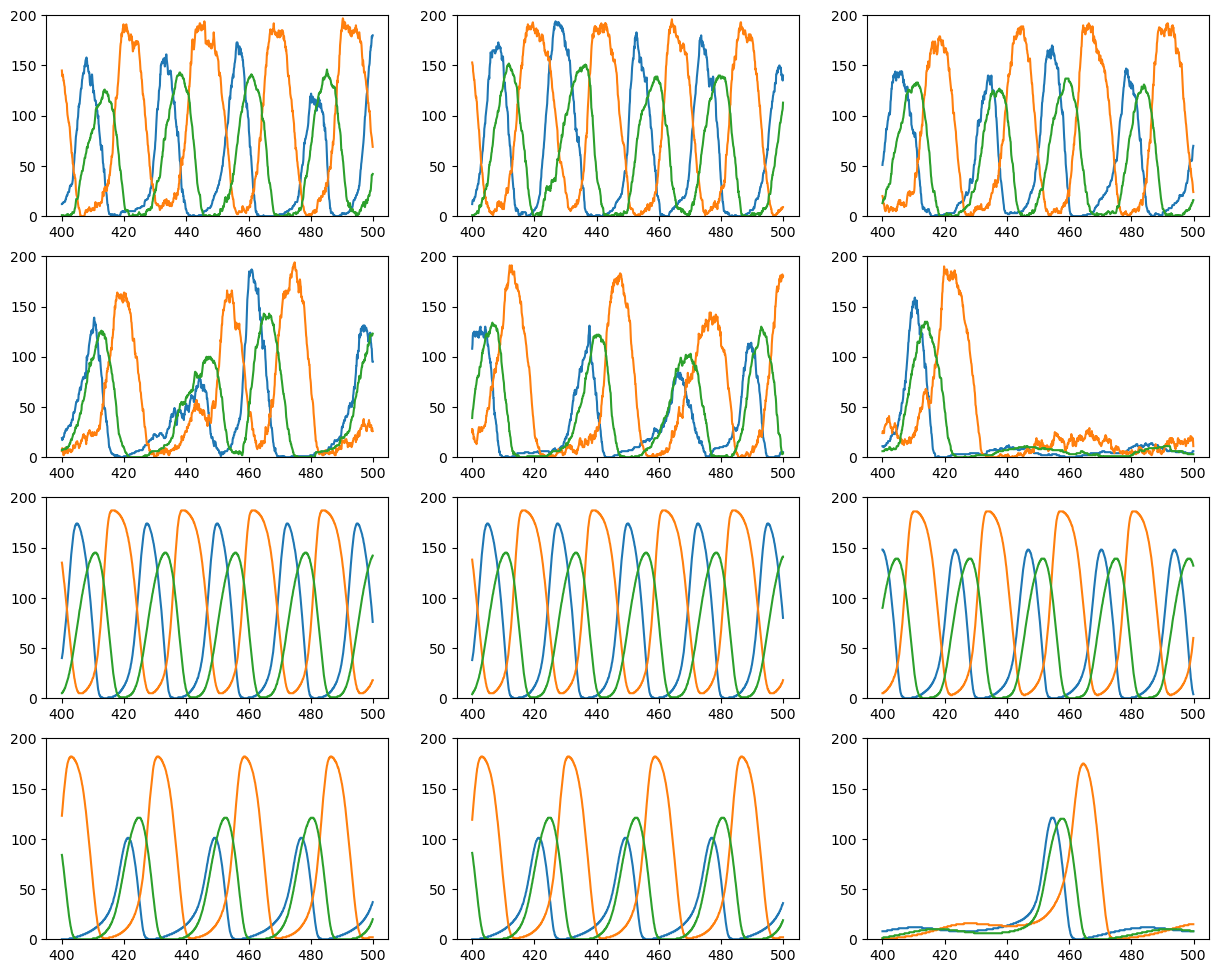

In [8]:
plt.figure(figsize=(15,12))

for num, cond in enumerate(conditions*2):
    ax = plt.subplot(4, 3, num+1)
    plt.plot(times[4000:5000],all_data.iloc[my_idx[num]][observables], label=num)
    plt.ylim(0,200)

## Objective: get sliding windows (vectors) of each species over full time series
Window size of 20 (`int(window / dt)`)  


In [9]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 2                    # window size in hours
time_step = 0.5               # time step between windows



In [10]:
win_len = int(window/dt)
half_window = int(win_len/2)
windows_idx = range(half_window,int(len(all_data)-half_window),int(time_step/dt))

### Functions for data transformation
* Min/Max scale 
* Drop unwanted columns
* Convert dataframe into stacks of vectors using sliding window

imported relevant functions from `model_fxns.py`

In [11]:
save_filepath = Path(SAVE_DIR,f'all_prot_{CURDATE}.csv')
if not save_filepath.exists() or OVERWRITE:
    all_prot_norm = minmax_scale(all_data)
    all_prot_norm = all_prot_norm[keep_obs]
    all_prot_tmp = stack_sliding_window(all_prot_norm, win_len, windows_idx)
else:
    all_prot_tmp = pd.read_csv(save_filepath, header=None)

In [12]:
all_prot_tmp.head()

,0,1,2,3,4,5,6,7,8,9,...,350,351,352,353,354,355,356,357,358,359
0,0.26087,0.26087,0.26087,0.26087,0.26087,0.260870,0.260870,0.260870,0.260870,0.260870,...,0.02,0.025,0.020,0.020,0.015,0.03,0.035,0.040,0.050,0.050
1,0.26087,0.26087,0.26087,0.26087,0.26087,0.260870,0.260870,0.260870,0.260870,0.260870,...,0.03,0.035,0.040,0.050,0.050,0.05,0.070,0.075,0.080,0.095
2,0.26087,0.26087,0.26087,0.26087,0.26087,0.239130,0.239130,0.239130,0.239130,0.239130,...,0.05,0.070,0.075,0.080,0.095,0.12,0.115,0.140,0.125,0.130
3,0.23913,0.23913,0.23913,0.23913,0.23913,0.239130,0.239130,0.239130,0.239130,0.239130,...,0.12,0.115,0.140,0.125,0.130,0.14,0.140,0.140,0.150,0.165
4,0.23913,0.23913,0.23913,0.23913,0.23913,0.282609,0.282609,0.282609,0.282609,0.282609,...,0.14,0.140,0.140,0.150,0.165,0.19,0.205,0.190,0.160,0.165


### Save the combined data file

In [13]:
save_filepath = Path(SAVE_DIR,f'all_prot_{CURDATE}.csv')
if not save_filepath.exists() or OVERWRITE:
    print(f'Saving file: {save_filepath}')
    np.savetxt(save_filepath, all_prot_tmp, delimiter=",")
else:
    print(f'File already exists: {save_filepath}... Skipping')

File already exists: /Users/darren/ECM_mod_output/all_prot_20230825.csv... Skipping


In [14]:
all_prot_tmp.shape

(479999, 360)

### Remove some rows of data
It appears there is an anomaly at the beginning (end?) of each condition; try to remove


In [15]:
stack_len = int((all_prot_tmp.shape[0]+1)/12)

drop_start_idx = np.concatenate([range(stack_len*i+2000,stack_len*i+stack_len-1) for i in range(12)])
drop_start_idx


array([  2000,   2001,   2002, ..., 479996, 479997, 479998])

In [16]:
# for_embedding = all_prot_tmp
for_embedding = all_prot_tmp.iloc[drop_start_idx]

## Stochastic simulations are in first half of array

In [17]:
int(len(for_embedding)/12)

37999

In [18]:
stoch_prot = for_embedding.iloc[:int(len(for_embedding)/2)]

### UMAP parameters

In [19]:
# umap params
neighbs = 25 # 25 (Austin's value)
min_d = 0.05 # 0.05 (Austin's value)
n_comp = 2
seed = 42
densmap = True # use DensMAP regularization with the default DensMAP parameter to better preserve local density; added 2023-08-25

metric = 'euclidean' # standard; what Austin used
# metric = 'manhattan'
# metric = 'mahalanobis'
# metric = 'canberra' # 
# metric = 'cosine' # 
# metric = 'correlation' #

# embedding save name
embedding_filename = f'embedding_{CURDATE}_{init_dt}_{dt}_{window}_{time_step}_{metric}_densmap{densmap}.csv'

In [20]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=n_comp,
        metric=metric,
        random_state=seed,
        low_memory=True        
        ).fit(stoch_prot)

embedding_stoch_prot = reducer.transform(stoch_prot)

In [21]:
embed_stoch_filepath = Path(SAVE_DIR,embedding_filename)
if not embed_stoch_filepath.exists() or OVERWRITE:
    print(f'Saving embedding to {embed_stoch_filepath}')
    np.savetxt(embed_stoch_filepath, embedding_stoch_prot, delimiter=",")
else:
    print(f'File already exists: {embedding_filename}... Skipping')

File already exists: embedding_20230825_0.1_0.1_2_0.5_euclidean_densmapTrue.csv... Skipping


#### Keep only a small region of ODE simulations to plot

In [22]:
ode_prot = for_embedding.iloc[int(len(for_embedding)/2+1):]
ode_stack_len = len(ode_prot)+1
ode_cond_len = int(ode_stack_len/6)
ode_keep_frac = 0.1
ode_keep_idx = np.concatenate([range(ode_cond_len*i,int(ode_cond_len*i+ode_cond_len*ode_keep_frac)) for i in range(6)])
# ode_idx = np.concatenate([range(ode_cond_len*i+3000,ode_cond_len*i+ode_cond_len-3001) for i in range(6)])


In [23]:
embedding_ode_prot = reducer.transform(ode_prot.iloc[ode_keep_idx])

In [24]:
embedding__ode_filename = str.replace(embedding_filename,'embedding','embedding_ode')
save_ode_embed_filepath = Path(SAVE_DIR,embedding__ode_filename)
if not save_ode_embed_filepath.exists() or OVERWRITE:
    print(f'Saving ode embedding to {save_ode_embed_filepath}')
    np.savetxt(save_ode_embed_filepath, embedding_ode_prot, delimiter=",")
else:
    print(f'File already exists: {embedding__ode_filename}... Skipping')

File already exists: embedding_ode_20230825_0.1_0.1_2_0.5_euclidean_densmapTrue.csv... Skipping


# Plot the embeddings

File already exists: /Users/darren/ECM_mod_output/UMAP_neighbs25_window2_tstep0.5_euclidean_densmapTrue_ORIG.png... Skipping


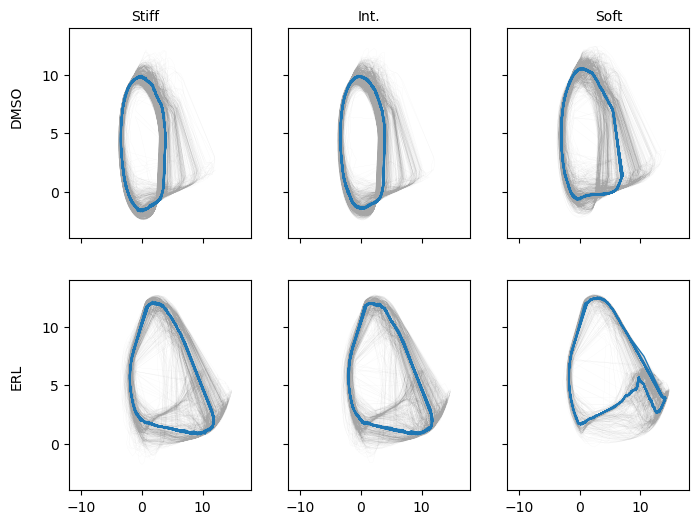

In [25]:
fig = plt.figure(figsize=(8,6))
n1 = 1
for n in range(6):
    plt.subplot(2,3,n1)
    trk_len = int(len(embedding_stoch_prot)/6)
    trk_len_ode = int(len(embedding_ode_prot)/6)
    plt.plot(embedding_stoch_prot[n*trk_len:n1*trk_len,0], embedding_stoch_prot[n*trk_len:n1*trk_len,1], lw=0.02, alpha=0.7, c='gray')
    plt.plot(embedding_ode_prot[n*trk_len_ode:n1*trk_len_ode,0], embedding_ode_prot[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-12,18)
    plt.ylim(-4,14)

    ax = plt.gca()
    if (n1 % 3) != 1:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<4:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

# Set common labels
fig.text(0.22, 0.9, 'Stiff', ha='center', va='center')
fig.text(0.5, 0.9, 'Int.', ha='center', va='center')
fig.text(0.8, 0.9, 'Soft', ha='center', va='center')
fig.text(0.06, 0.3, 'ERL', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.75, 'DMSO', ha='center', va='center', rotation='vertical')

umap_plot_filepath = Path(SAVE_DIR, f"UMAP_neighbs{neighbs}_window{window}_tstep{time_step}_{metric}_densmap{densmap}_ORIG.png")

if not umap_plot_filepath.exists() or OVERWRITE:
    print(f'Saving UMAP image to {umap_plot_filepath}')
    plt.savefig(umap_plot_filepath, bbox_inches='tight')
else:
    print(f'File already exists: {umap_plot_filepath}... Skipping')
